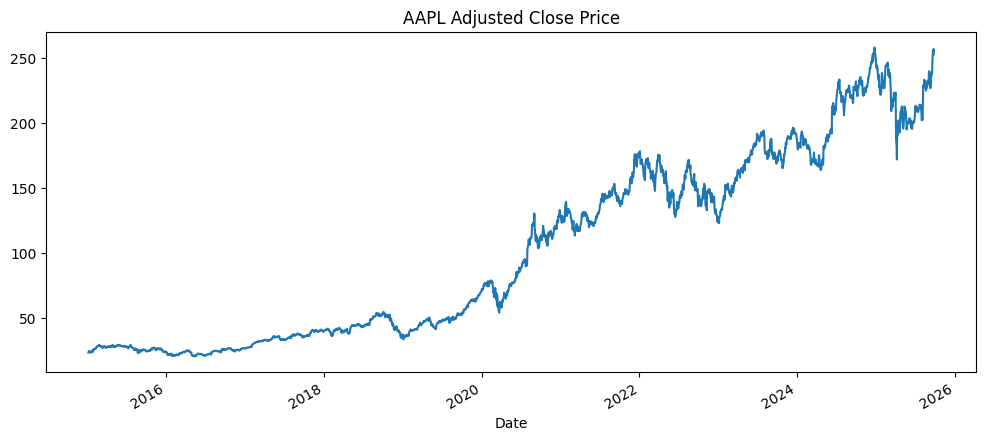

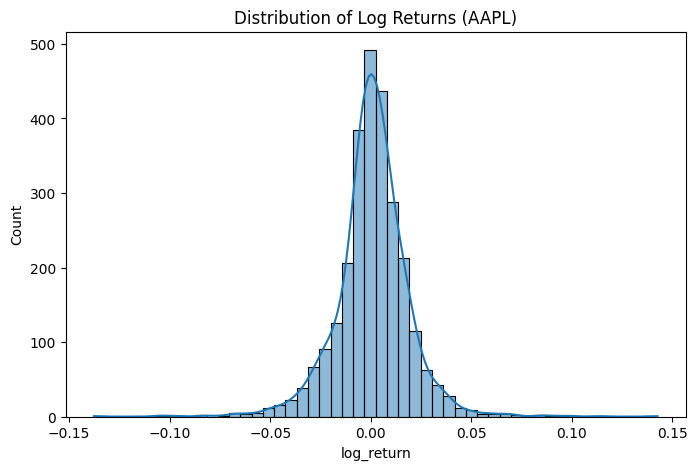

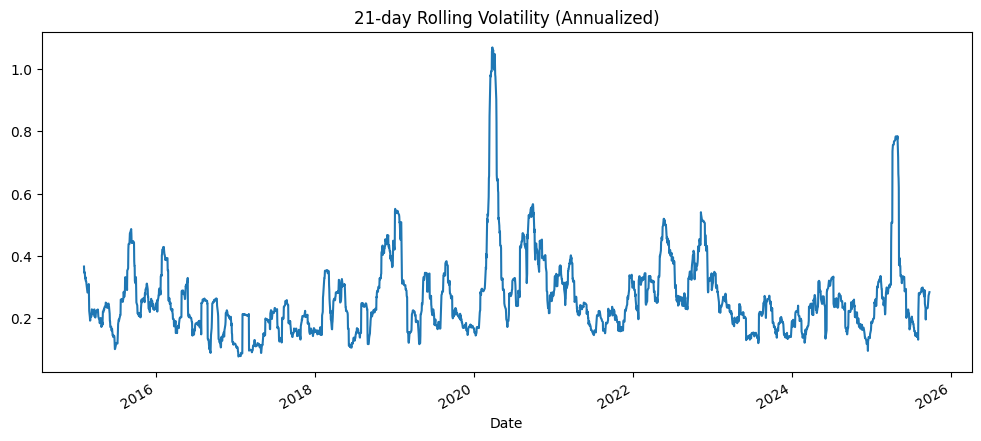

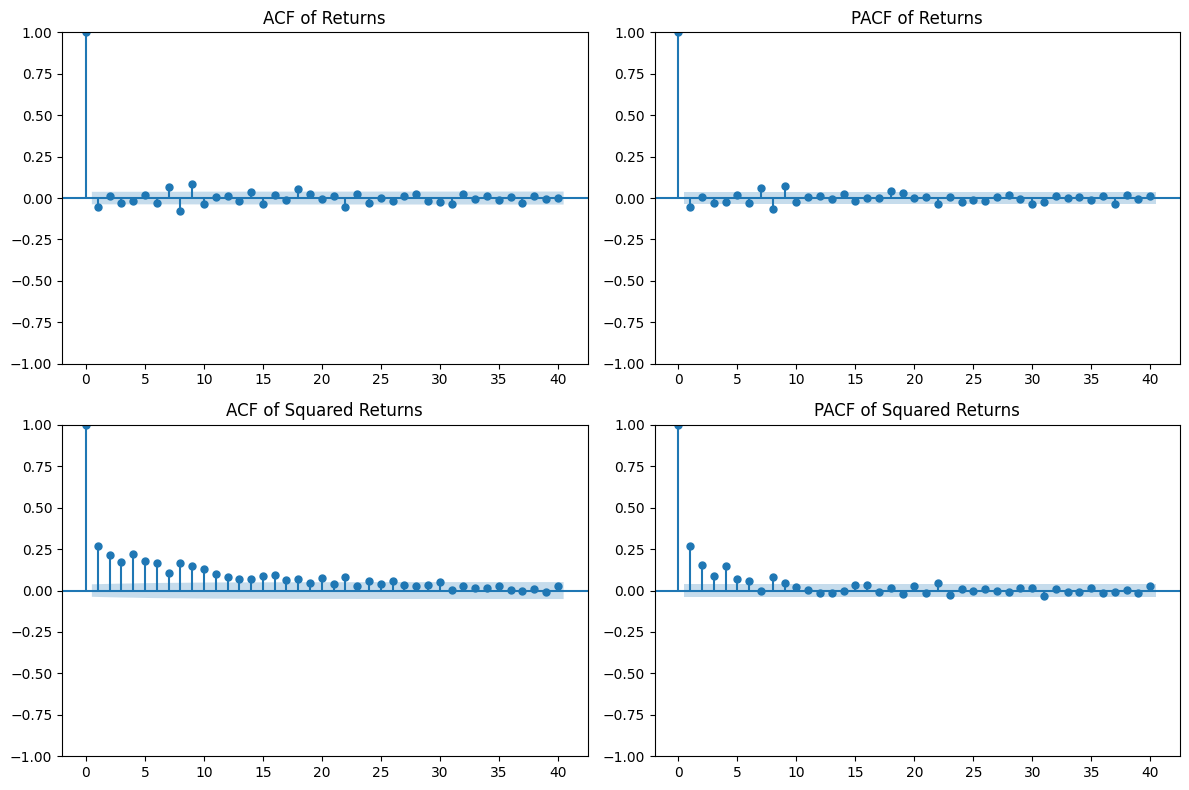

ADF Statistic: -16.721001702328266
p-value: 1.4085923233449172e-29

ARCH Test Results
LM stat: 370.98051265584314
p-value: 1.3966707197227497e-73


In [3]:
# 01_data_eda.ipynb

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.stats.diagnostic import het_arch

# Load processed data
aapl = pd.read_csv("../data/processed/AAPL_processed.csv", parse_dates=["Date"])
sp500 = pd.read_csv("../data/processed/GSPC_processed.csv", parse_dates=["Date"])

# Pick one dataset for now
df = aapl.copy()
df.set_index("Date", inplace=True)

# --- 1. Plot Adjusted Close Price ---
plt.figure(figsize=(12,5))
df["Adj Close"].plot(title="AAPL Adjusted Close Price")
plt.show()

# --- 2. Plot Log Returns Histogram ---
plt.figure(figsize=(8,5))
sns.histplot(df["log_return"], bins=50, kde=True)
plt.title("Distribution of Log Returns (AAPL)")
plt.show()

# --- 3. Rolling Volatility (21-day Std Dev) ---
df["rolling_vol"] = df["log_return"].rolling(21).std() * np.sqrt(252)  # annualized
plt.figure(figsize=(12,5))
df["rolling_vol"].plot(title="21-day Rolling Volatility (Annualized)")
plt.show()

# --- 4. ACF/PACF of Returns & Squared Returns ---
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2,2, figsize=(12,8))
plot_acf(df["log_return"].dropna(), lags=40, ax=axes[0,0])
axes[0,0].set_title("ACF of Returns")

plot_pacf(df["log_return"].dropna(), lags=40, ax=axes[0,1])
axes[0,1].set_title("PACF of Returns")

plot_acf(df["squared_return"].dropna(), lags=40, ax=axes[1,0])
axes[1,0].set_title("ACF of Squared Returns")

plot_pacf(df["squared_return"].dropna(), lags=40, ax=axes[1,1])
axes[1,1].set_title("PACF of Squared Returns")

plt.tight_layout()
plt.show()

# --- 5. Stationarity Test (ADF) ---
adf_result = adfuller(df["log_return"].dropna())
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

# --- 6. ARCH Test (Engle’s Test for ARCH effects) ---
arch_test = het_arch(df["log_return"].dropna())
print("\nARCH Test Results")
print("LM stat:", arch_test[0])
print("p-value:", arch_test[1])
